# 03 · Simulación interactiva

Actividad 6 y entregable E3. Se puede cambiar el punto objeto $P$, el índice $n_L$, las caras $g(x)$ y $f(x)$ y las direcciones $\hat u$ de los rayos. La figura muestra los rayos incidentes (azul), los tramos dentro del vidrio (naranja) y los emergentes (aqua), y marca la imagen.

- La imagen es el cruce de los rayos 1 y 2, como en el ejemplo resuelto. El abanico muestra el resto de rayos que llegan a la lente.
- La imagen paraxial (matrices ABCD) es la referencia: la diferencia con ella mide la aberración.
- La misma simulación está en la página web del proyecto, para probarla desde el celular: <https://oswaldoaqm.github.io/Proyecto-Opticas/>. La página usa una versión en JavaScript del trazador que `tests/test_web.py` compara con este paquete.

Los controles necesitan Jupyter (por ejemplo `jupyter lab`). En GitHub solo se ve la figura fija.

In [1]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display

from lentes import lente_biconvexa
from lentes.estilo import aplicar_estilo
from lentes.simulacion import dibujar_escena, escena, lente_desde_formulas, resumen

aplicar_estilo()

## Vista fija: el ejemplo resuelto

Lente de caras parabólicas ($R = 10$, $d = 2$, $n_L = 1.5$) y rayos a $+2^\circ$ y $-2^\circ$ desde $P = (0, -30)$, como en el notebook 01.

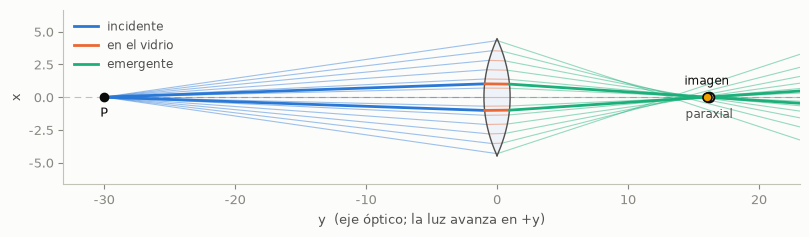

Imagen con los rayos 1 y 2: (0.000, 16.029), real
Imagen paraxial: (0.000, 16.187), aumento -0.535
Diferencia: Δy = -0.158, Δx = 0.000
Focal efectiva: 10.345


In [2]:
lente = lente_biconvexa(R1=10, R2=10, espesor=2, n=1.5, k1=-1, k2=-1)
esc = escena(lente, P=(0, -30), alfas_grados=(2, -2), n_abanico=13)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
dibujar_escena(ax, esc)
plt.show()
print(resumen(esc))

## Panel con controles

Las caras pueden ser cónicas, con radio de vértice $R$ y constante cónica $k$ ($k = 0$ es una esfera, $k = -1$ una parábola), o cualquier fórmula en $x$ escrita como en Python (`1 - x**2/20`; también vale `^`). Los ángulos $\alpha$ de los rayos 1 y 2 se miden desde el eje óptico: $\hat u = (\sin\alpha, \cos\alpha)$.

In [ ]:
opciones = dict(continuous_update=False, style={"description_width": "130px"},
                layout=widgets.Layout(width="420px"))
xP = widgets.FloatSlider(value=0, min=-8, max=8, step=0.05, description="x_P", **opciones)
yP = widgets.FloatSlider(value=-30, min=-90, max=-1.5, step=0.1, description="y_P", **opciones)
nL = widgets.FloatSlider(value=1.5, min=1.0, max=2.5, step=0.01, description="n_L", **opciones)
a1 = widgets.FloatSlider(value=2, min=-30, max=30, step=0.1, description="rayo 1: α₁ (°)", **opciones)
a2 = widgets.FloatSlider(value=-2, min=-30, max=30, step=0.1, description="rayo 2: α₂ (°)", **opciones)
abanico = widgets.IntSlider(value=13, min=0, max=41, description="rayos del abanico", **opciones)

modo = widgets.ToggleButtons(options=[("Cónicas", "conica"), ("Fórmulas", "formula")], value="conica")
R1 = widgets.FloatSlider(value=10, min=3, max=60, step=0.1, description="R₁ (cara g)", **opciones)
k1 = widgets.FloatSlider(value=-1, min=-5, max=2, step=0.01, description="k₁ (cara g)", **opciones)
R2 = widgets.FloatSlider(value=10, min=3, max=60, step=0.1, description="R₂ (cara f)", **opciones)
k2 = widgets.FloatSlider(value=-1, min=-5, max=2, step=0.01, description="k₂ (cara f)", **opciones)
d = widgets.FloatSlider(value=2, min=0.2, max=8, step=0.05, description="espesor d", **opciones)
g = widgets.Text(value="-1 + x**2/20 - x**4/6000", description="g(x)", **opciones)
f = widgets.Text(value="1 - x**2/20 + x**4/6000", description="f(x)", **opciones)
caras = widgets.Stack([widgets.VBox([R1, k1, R2, k2, d]), widgets.VBox([g, f])], selected_index=0)
salida = widgets.Output()


def construir_lente():
    if modo.value == "conica":
        return lente_biconvexa(R1.value, R2.value, d.value, n=nL.value, k1=k1.value, k2=k2.value)
    return lente_desde_formulas(g.value, f.value, n=nL.value)


# La figura y el texto se escriben en `salida` con append_*, no con `with salida:`.
# Ejecutado con nbconvert (como en el CI), `with salida:` a veces deja la ejecución colgada.
def actualizar(*_):
    caras.selected_index = 0 if modo.value == "conica" else 1
    salida.outputs = ()
    try:
        lente = construir_lente()
    except Exception as error:  # caras que no se juntan, fórmula mal escrita, ...
        salida.append_stdout(f"No se puede armar la lente: {error}\n")
        return
    P = (xP.value, min(yP.value, lente.y_min - 0.25))  # P siempre debajo de la lente
    esc = escena(lente, P, (a1.value, a2.value), abanico.value)
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    dibujar_escena(ax, esc)
    salida.append_display_data(fig)
    plt.close(fig)
    salida.append_stdout(resumen(esc) + "\n")


for control in (xP, yP, nL, a1, a2, abanico, modo, R1, k1, R2, k2, d, g, f):
    control.observe(actualizar, names="value")

display(widgets.VBox([
    widgets.HTML("<b>Objeto P</b>"), xP, yP,
    widgets.HTML("<b>Lente</b>"), nL, modo, caras,
    widgets.HTML("<b>Rayos</b>"), a1, a2, abanico,
    salida,
]))
actualizar()

## Qué probar

- Acercar $P$ a la lente: cuando pasa el foco $F$ (en $y \approx -10.7$ para la lente del ejemplo) la imagen se vuelve virtual.
- Poner $k_1 = k_2 = 0$ (caras esféricas) con rayos a $\pm 7^\circ$: la imagen paraxial no cambia y la de los rayos 1 y 2 se adelanta unas 3.7 unidades. Con $k = -2.33$ la diferencia casi desaparece (notebook 02).
- Subir $n_L$ a 2.4 con caras esféricas de radio 6, $P = (0, -8)$ y el rayo 1 a $19^\circ$: el rayo se refleja dentro de la lente (reflexión total) y no forma imagen.
- En el modo de fórmulas, las caras de ejemplo son una parábola más un término en $x^4$, como se especifican las lentes asféricas.